# c1 · Step 1: Data exploration

Every section answers one question and ends with **finding → decision**.
Decisions that need a model to test are only *flagged* here and tested in later notebooks.

| # | Question | Feeds |
|---|---|---|
| 1 | What did we download? | loader (c3) |
| 2 | Class distribution | metric (c2), loss (c6) |
| 3 | What do the images look like? | augmentation (c8) |
| 4 | Image properties, and do they differ per class? | preprocessing (c3, c5) |
| 5 | Pixel values | normalisation (c3) |
| 6 | Near-duplicates across splits | evaluation set (c2), report |

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
sys.path.insert(0, "..")
from lib.data import DATA_ROOT, ARTIFACTS, SPLITS, CLASSES, SEED, list_split
rng = np.random.default_rng(SEED)
pd.set_option("display.precision", 3)
print(sorted(p.name for p in DATA_ROOT.iterdir()))

['README.md', 'class_distribution.csv', 'class_distribution_final.png', 'model_benchmark.csv', 'model_benchmark.png', 'test', 'train', 'val']


## 1. Inventory: one row per image
Data was downloaded and checksum-verified by `early/s1_data-explore.ipynb` (same zip, SHA-256 checked).
One pass over all files: header metadata, a check whether "RGB" images really contain colour, and a
128×128 grayscale thumbnail reused below.

In [2]:
rows, thumbs = [], []
for split in SPLITS:
    for p, c in list_split(split):
        with Image.open(p) as im:
            rgb = np.asarray(im.convert("RGB"), dtype=np.int16)
            rows.append(dict(path=str(p.relative_to(DATA_ROOT)), split=split, cls=CLASSES[c], w=im.width,
                             h=im.height, mode=im.mode, ext=p.suffix.lower(), kb=p.stat().st_size / 1024,
                             chroma=int(np.abs(rgb - rgb.mean(2, keepdims=True)).max())))
            thumbs.append(np.asarray(im.convert("L").resize((128, 128), Image.BILINEAR)))
df = pd.DataFrame(rows)
df["cls"] = pd.Categorical(df.cls, CLASSES); df["split"] = pd.Categorical(df.split, SPLITS)
X = np.stack(thumbs)
print(df.shape, "| extensions:", df.ext.value_counts().to_dict(), "| unreadable files: 0")

(5941, 9) | extensions: {'.jpg': 5940, '.jpeg': 1} | unreadable files: 0


## 2. Class distribution

In [3]:
counts = pd.crosstab(df.cls, df.split, margins=True, margins_name="total")
display(counts)
display(pd.crosstab(df.cls, df.split, normalize="columns").mul(100).round(1).rename(columns=lambda c: c + " %"))
tr = counts.loc[CLASSES, "train"]
print(f"imbalance ratio {tr.max() / tr.min():.2f} | majority-class accuracy on val "
      f"{(df[df.split == 'val'].cls == 'glioma').mean():.3f}")

split,train,val,test,total
cls,,,,
glioma,1534,329,328,2191
meningioma,1035,222,221,1478
no_tumor,551,118,118,787
pituitary,1040,223,222,1485
total,4160,892,889,5941


split,train %,val %,test %
cls,,,
glioma,36.9,36.9,36.9
meningioma,24.9,24.9,24.9
no_tumor,13.2,13.2,13.3
pituitary,25.0,25.0,25.0


imbalance ratio 2.78 | majority-class accuracy on val 0.369


**Finding.** The split is stratified exactly 70/15/15 per class. Imbalance ratio 2.78 (glioma 36.9 %,
no_tumor 13.2 %). Always predicting glioma gives 0.369 accuracy.

**Decisions.**
* **Keep the official split.** Options were keep / re-split by image / re-split by patient. A patient-level
  re-split is impossible (no patient IDs), and an image-level re-split gains nothing and loses comparability.
* Imbalance is handled where it belongs: metric choice in **c2**, loss/sampler experiment in **c6**.
  Val and test are never rebalanced.

## 3. What do the images look like?

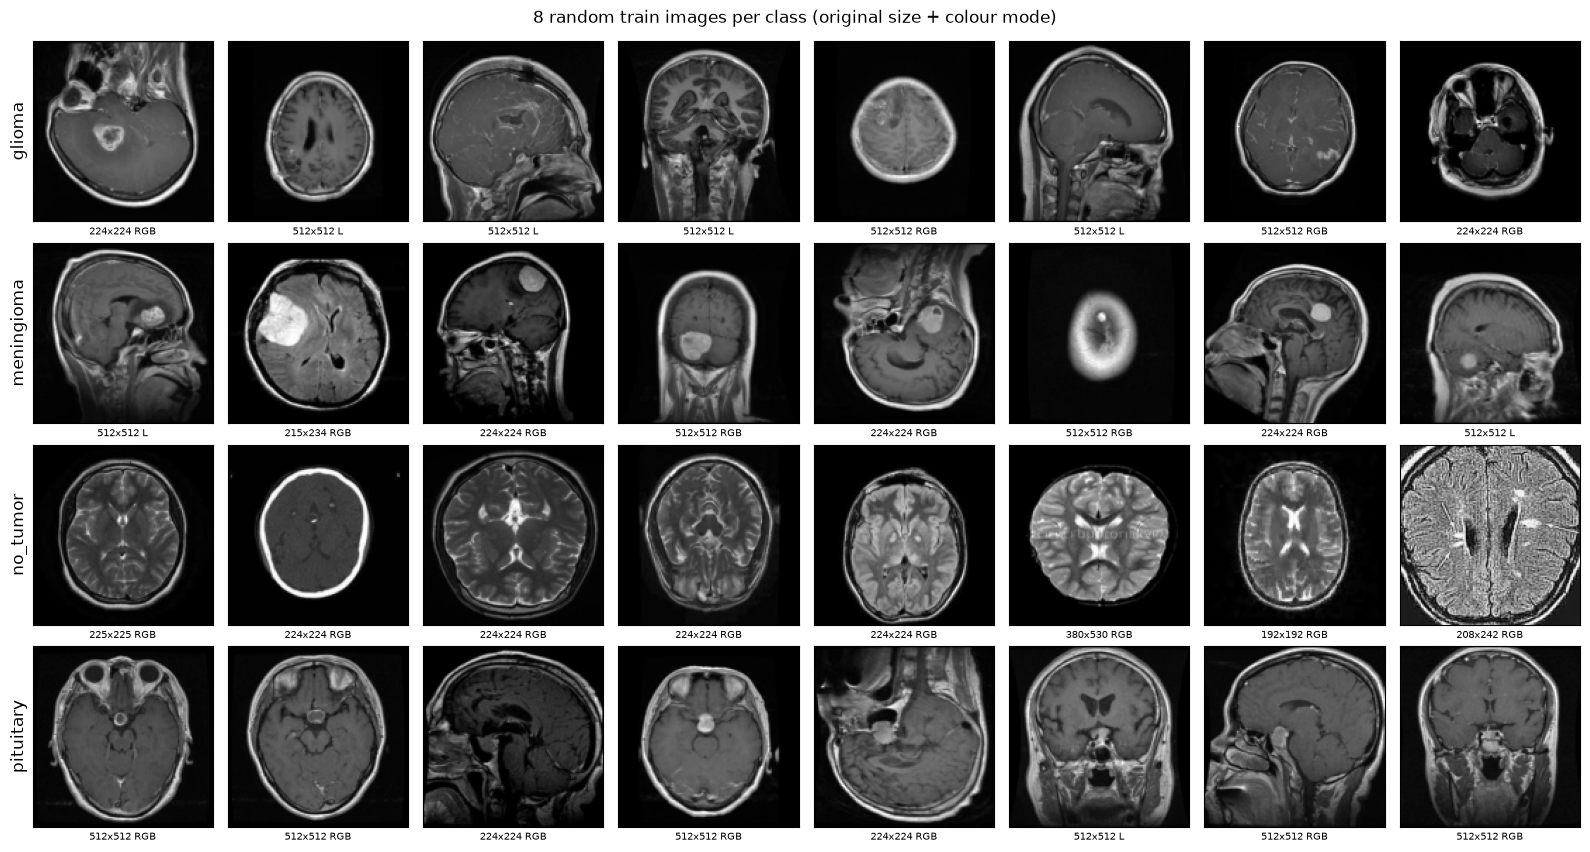

In [4]:
fig, axes = plt.subplots(4, 8, figsize=(16, 8.6))
for r, cls in enumerate(CLASSES):
    sub = df[(df.split == "train") & (df.cls == cls)]
    for c, i in enumerate(rng.choice(sub.index, 8, replace=False)):
        axes[r, c].imshow(X[i], cmap="gray"); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, c].set_xlabel(f"{df.w[i]}x{df.h[i]} {df['mode'][i]}", fontsize=7)
        if c == 0: axes[r, c].set_ylabel(cls, fontsize=12)
plt.suptitle("8 random train images per class (original size + colour mode)"); plt.tight_layout(); plt.show()

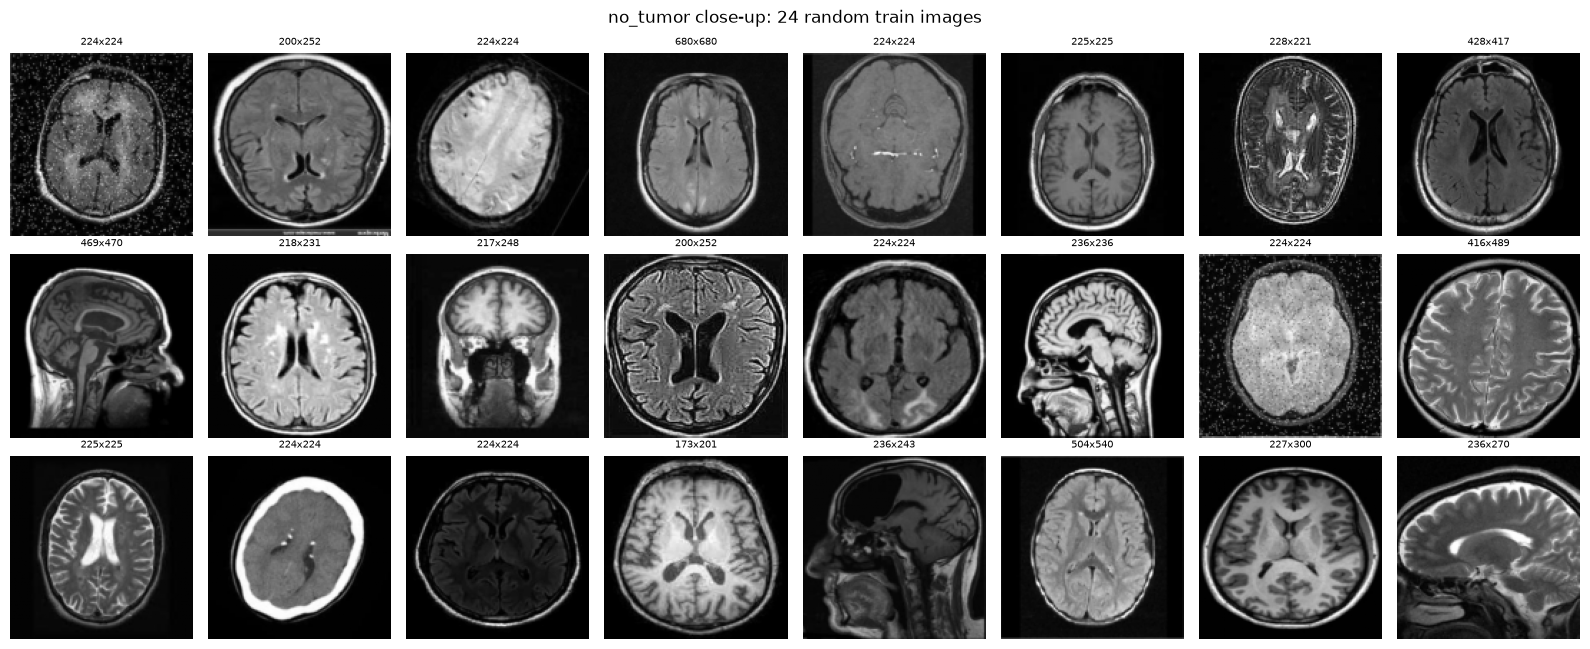

In [5]:
sub = df[(df.split == "train") & (df.cls == "no_tumor")]
fig, axes = plt.subplots(3, 8, figsize=(16, 6.6))
for ax, i in zip(axes.ravel(), rng.choice(sub.index, 24, replace=False)):
    ax.imshow(X[i], cmap="gray"); ax.axis("off"); ax.set_title(f"{df.w[i]}x{df.h[i]}", fontsize=7)
plt.suptitle("no_tumor close-up: 24 random train images"); plt.tight_layout(); plt.show()

**Findings.**
* All three views (axial, coronal, sagittal) appear in every class.
* The tumour classes look like T1 contrast-enhanced MRI. **no_tumor is a mix**: T2 (bright CSF), FLAIR,
  non-contrast T1, **CT scans**, odd crops and watermarked images. So the classes differ not only in pathology
  but in *how the images were acquired*.

**Decisions.**
* Horizontal flip is anatomically plausible for all three views (left/right symmetry; sagittal images face both
  ways in the data). Vertical flips are not. → augmentation candidates for **c8**.
* The modality mix in no_tumor is a label-correlated difference that preprocessing cannot remove (it is the
  image content). It is a **shortcut risk** that is measured with a probe in **c5** and reported as a limitation.

## 4. Image properties, and do they differ per class?
A CNN learns *any* systematic difference between classes. If a property such as resolution or colour mode
differs per class, the model can use it instead of anatomy, and because the same bias is in val and test,
the score would not reveal it.

In [6]:
df["res"] = (df.w.astype(str) + "x" + df.h.astype(str)).where(lambda s: s.isin(["512x512", "224x224"]), "other")
df["square"] = df.w == df.h
df["has_colour"] = df.chroma > 2
print("resolution (row %)"); display(pd.crosstab(df.cls, df.res, normalize="index").mul(100).round(1))
print("stored colour mode (row %)"); display(pd.crosstab(df.cls, df["mode"], normalize="index").mul(100).round(1))
display(df.groupby("cls", observed=True)[["square", "has_colour", "kb"]].mean())
print(f"{df[['w', 'h']].drop_duplicates().shape[0]} distinct resolutions")

resolution (row %)


res,224x224,512x512,other
cls,,,
glioma,36.0,62.0,2.0
meningioma,27.7,64.1,8.2
no_tumor,36.0,0.5,63.5
pituitary,32.1,66.4,1.5


stored colour mode (row %)


mode,L,RGB,RGBA
cls,,,
glioma,41.7,58.3,0.0
meningioma,32.6,67.4,0.0
no_tumor,0.5,99.1,0.4
pituitary,27.0,73.0,0.0


,square,has_colour,kb
cls,,,
glioma,0.984,0.000,15.706
meningioma,0.929,0.000,18.337
no_tumor,0.550,0.041,19.496
pituitary,0.998,0.000,23.537


349 distinct resolutions


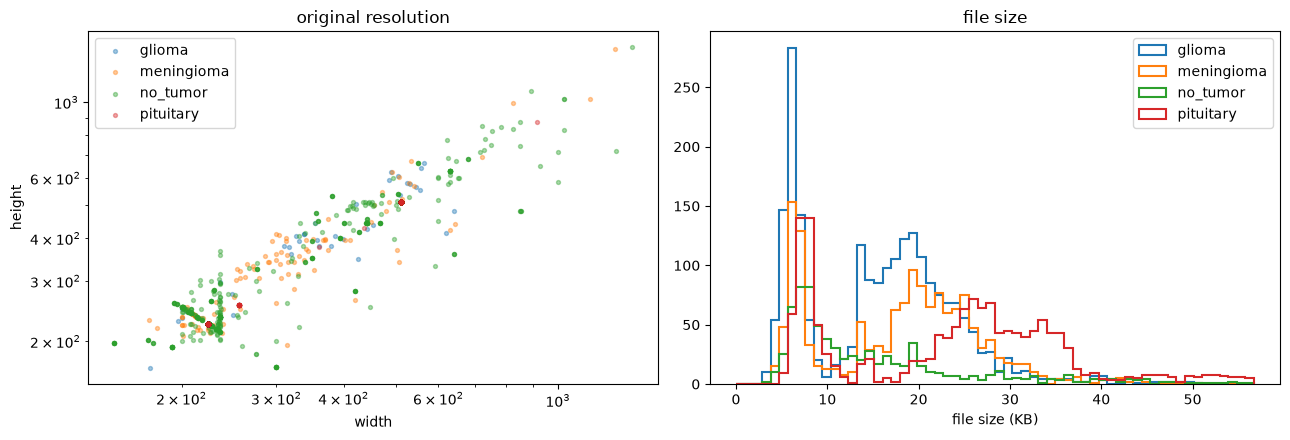

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for cls in CLASSES:
    s = df[df.cls == cls]
    ax[0].scatter(s.w, s.h, s=8, alpha=0.4, label=cls)
    ax[1].hist(s.kb, bins=60, range=(0, df.kb.quantile(0.99)), histtype="step", lw=1.5, label=cls)
ax[0].set(xscale="log", yscale="log", xlabel="width", ylabel="height", title="original resolution")
ax[1].set(xlabel="file size (KB)", title="file size"); ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

**Test: metadata-only classifier.** How well can the label be predicted from width, height, aspect ratio,
file size and colour flags alone, *without any pixels*? Chance is 0.25 balanced accuracy.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, classification_report
meta = pd.DataFrame({"w": df.w, "h": df.h, "aspect": df.w / df.h, "kb": df.kb,
                     "is_L": (df["mode"] == "L").astype(int), "has_colour": df.has_colour.astype(int)})
tr_m, va_m = df.split == "train", df.split == "val"
rf = RandomForestClassifier(300, class_weight="balanced", random_state=SEED).fit(meta[tr_m], df.cls[tr_m])
pred = rf.predict(meta[va_m])
print(f"metadata-only balanced accuracy on val: {balanced_accuracy_score(df.cls[va_m], pred):.3f}")
print(classification_report(df.cls[va_m], pred, digits=3))

metadata-only balanced accuracy on val: 0.549
              precision    recall  f1-score   support

      glioma      0.525     0.505     0.515       329
  meningioma      0.361     0.374     0.367       222
    no_tumor      0.718     0.712     0.715       118
   pituitary      0.590     0.605     0.597       223

    accuracy                          0.525       892
   macro avg      0.548     0.549     0.549       892
weighted avg      0.526     0.525     0.525       892



**Findings.**
* no_tumor: 64 % have a non-standard resolution, 45 % are non-square, 99 % are stored as RGB and 4 % contain
  real colour. Tumour classes: 62-66 % are 512×512, ≥ 93 % square, none contain colour.
* **Metadata-only random forest: 0.549 balanced accuracy on val** (chance 0.25), no_tumor recall 0.71,
  without seeing a single pixel.

**Decisions.**
* **Convert everything to one grayscale channel.** No tumour image contains colour, so nothing is lost, and the
  colour/mode cue disappears. (Grayscale vs 3 channels is still tested in **c5**, as planned.)
* **Resize every image to one fixed square size.** How to get there is a real choice: *stretch* distorts the
  non-square (mostly no_tumor) images, *pad* adds black bars (mostly to no_tumor). Both leave a class cue.
  A third option, *crop to the head then pad*, removes most framing differences. → tested in **c5** with a
  shortcut probe, because val accuracy alone cannot detect a shortcut that is present in val too.

## 5. Pixel values

mean_px        frac_black       
              mean    std       mean    std
cls                                        
glioma       0.141  0.057      0.472  0.154
meningioma   0.175  0.064      0.436  0.158
no_tumor     0.234  0.089      0.306  0.209
pituitary    0.192  0.054      0.299  0.137

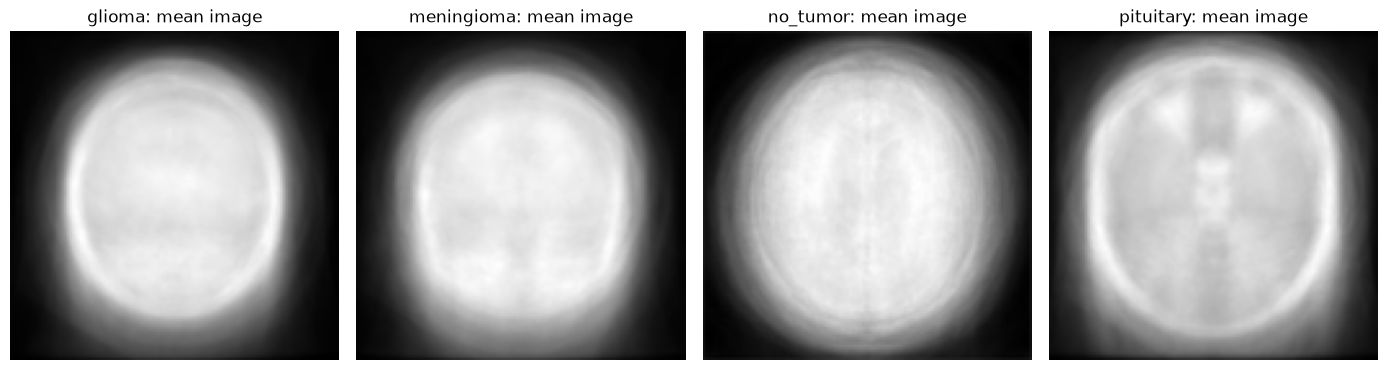

In [9]:
Xf = X.astype(np.float32) / 255
df["mean_px"] = Xf.mean((1, 2)); df["frac_black"] = (X < 10).mean((1, 2))
display(df.groupby("cls", observed=True)[["mean_px", "frac_black"]].agg(["mean", "std"]))
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, cls in zip(axes, CLASSES):
    m = ((df.cls == cls) & (df.split == "train")).to_numpy()
    ax.imshow(Xf[m].mean(0), cmap="gray"); ax.set_title(f"{cls}: mean image"); ax.axis("off")
plt.tight_layout(); plt.show()

**Findings.** no_tumor images are brighter on average (0.234 vs 0.14-0.19) and the black-background share
differs by class (30-47 %). Part of this is the T2/FLAIR content, part is framing.

**Decisions.**
* Normalise with the **train** mean/std (computed in c3, never on val/test).
* Two options that could remove part of the brightness/framing cue are tested in **c5**: cropping to the head
  bounding box, and per-image normalisation instead of a global one.

## 6. Near-duplicates across splits (leakage)
For every val/test image: Pearson correlation of 32×32 thumbnails with its most similar **train** image.
(A 64-bit perceptual hash does not work here: the black background makes unrelated scans hash alike.)
Options for what to do with near-duplicates:

| Option | Pro | Con |
|---|---|---|
| A. keep everything | official split, comparable | memorised copies inflate val/test, favour overfitting |
| B. drop near-duplicates from val/test | honest generalisation estimate | slightly smaller eval sets |
| C. B for model selection, report test both ways | honest selection + comparability | two test numbers to explain |

The threshold is chosen by **looking at pairs** in correlation bins below.

In [10]:
def vecs(size=32):
    v = np.stack([np.asarray(Image.fromarray(x).resize((size, size), Image.BILINEAR), np.float32).ravel() for x in X])
    v -= v.mean(1, keepdims=True)
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-8)
V = vecs()
itr = np.where(df.split == "train")[0]
near = []
for split in ["val", "test"]:
    ib = np.where(df.split == split)[0]
    C = V[itr] @ V[ib].T
    near.append(pd.DataFrame({"i": itr[C.argmax(0)], "j": ib, "corr": C.max(0), "split": split}))
near = pd.concat(near, ignore_index=True)
near["same_label"] = df.cls.values[near.i] == df.cls.values[near.j]
bins = [0.9, 0.95, 0.97, 0.98, 0.99, 1.001]
display(pd.crosstab(pd.cut(near["corr"], bins, right=False), near.split, margins=True))

split,test,val,All
corr,,,
"[0.9, 0.95)",291,302,593
"[0.95, 0.97)",191,207,398
"[0.97, 0.98)",91,77,168
"[0.98, 0.99)",47,47,94
"[0.99, 1.001)",9,13,22
All,629,646,1275


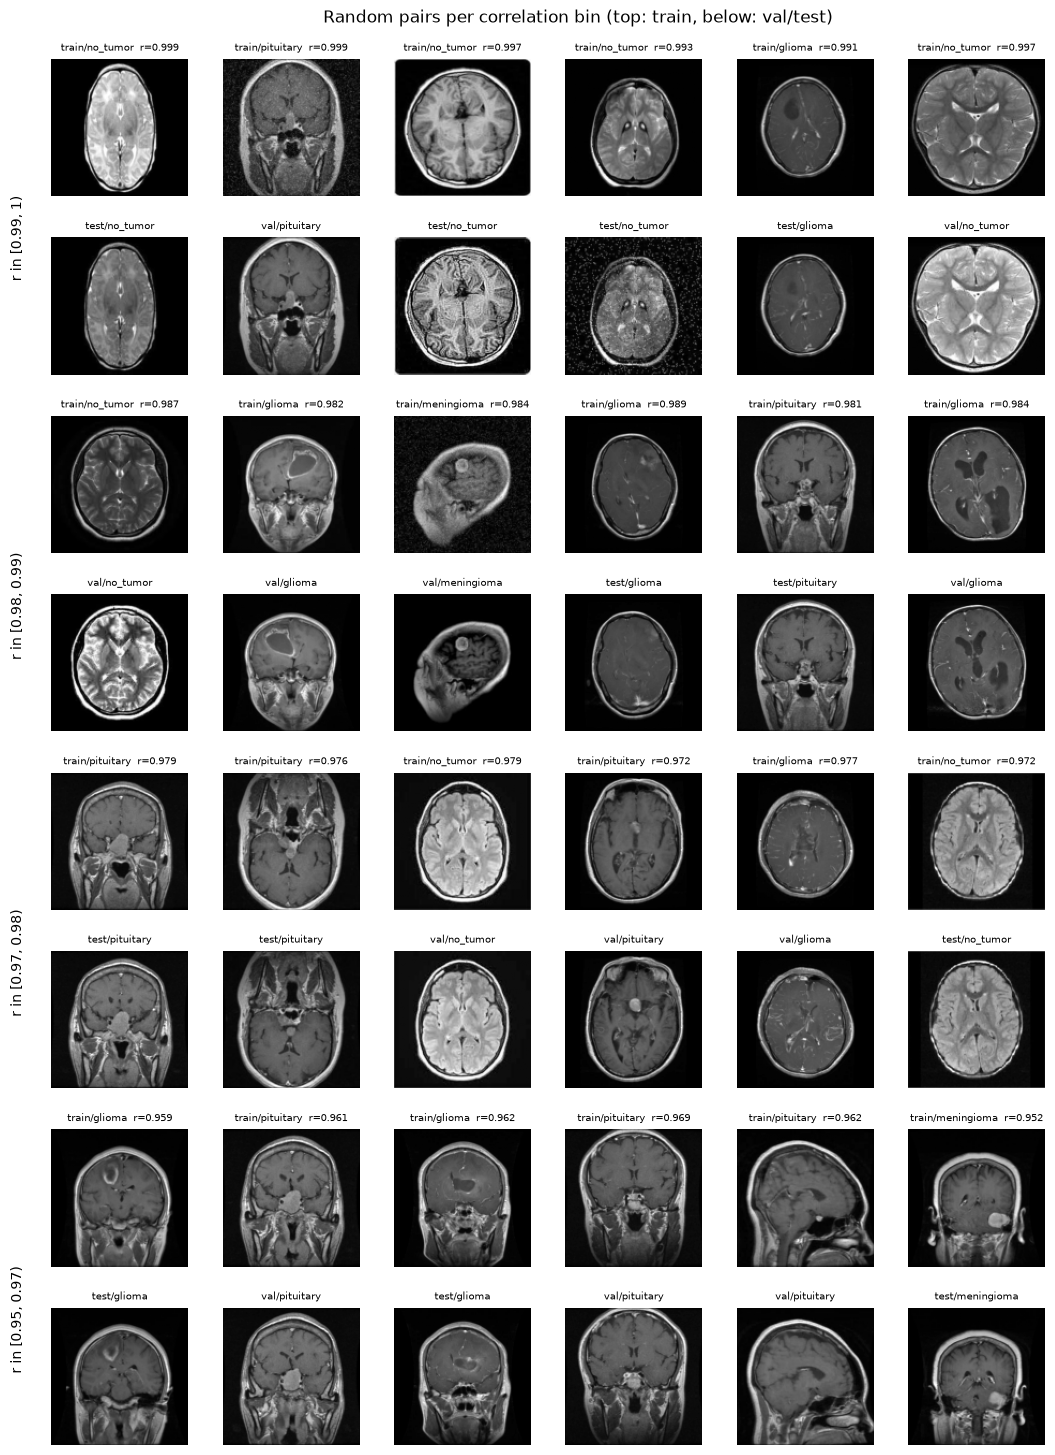

In [11]:
fig, axes = plt.subplots(2 * 4, 6, figsize=(12, 16.5))
for b, (lo, hi) in enumerate([(0.99, 1.01), (0.98, 0.99), (0.97, 0.98), (0.95, 0.97)]):
    sel = near[(near["corr"] >= lo) & (near["corr"] < hi)]
    sel = sel.sample(min(6, len(sel)), random_state=SEED)
    for k in range(6):
        for r in range(2):
            ax = axes[2 * b + r, k]; ax.axis("off")
            if k < len(sel):
                idx = int(sel.iloc[k].i if r == 0 else sel.iloc[k].j)
                ax.imshow(X[idx], cmap="gray")
                ax.set_title(f"{df.split[idx]}/{df.cls[idx]}" + (f"  r={sel.iloc[k]['corr']:.3f}" if r == 0 else ""), fontsize=7)
    axes[2 * b, 0].text(-0.3, 0, f"r in [{lo}, {min(hi, 1)})", transform=axes[2 * b, 0].transAxes, fontsize=10,
                        rotation=90, va="top")
plt.suptitle("Random pairs per correlation bin (top: train, below: val/test)")
plt.subplots_adjust(wspace=0.05, hspace=0.3, top=0.95, left=0.05); plt.show()

**What the bins show.**
* **r ≥ 0.98:** visually the *same image* (same slice; noise added, re-cropped or re-exported). Clear duplicates.
* **0.95-0.98:** mostly the *same patient and tumour* at a neighbouring slice. This is patient-level leakage.
* below 0.95: increasingly different scans.

no_tumor is over-represented among the duplicates: 22 of 118 val no_tumor images (19 %) have a train copy at
r ≥ 0.98, versus 7 % of val overall. That would inflate no_tumor recall in particular.

**Decision: option C with threshold 0.98.**
* 60 val and 56 test images that are clearly copies of a train image are excluded from the **clean** val/test sets
  (`artifacts/near_duplicates.json`). Model selection uses clean val (832 images, 96 no_tumor).
* The test set will be reported both ways (official and clean).
* Patient-level leakage (0.95-0.98 and below) **cannot** be removed without patient IDs. It inflates absolute
  scores for every model, so it is a stated limitation, not something the comparisons can fix.

In [12]:
THRESH = 0.98
flag = near[near["corr"] >= THRESH]
print(flag.groupby("split").size().to_dict(), "flagged | label mismatches:", (~flag.same_label).sum())
display(pd.crosstab(df.cls.values[flag.j], flag.split))
ARTIFACTS.mkdir(exist_ok=True)
_ = (ARTIFACTS / "near_duplicates.json").write_text(json.dumps(
    {"threshold": THRESH, "method": "max Pearson r of 32x32 grayscale thumbnails vs train",
     "exclude": sorted(df.path.values[flag.j].tolist())}, indent=1))

{'test': 56, 'val': 60} flagged | label mismatches: 1


split,test,val
row_0,,
glioma,19,17
meningioma,3,6
no_tumor,13,22
pituitary,21,15


## Findings → decisions

| Finding | Decision | Where |
|---|---|---|
| Official split is stratified 70/15/15 | keep it; never rebalance val/test | all |
| Imbalance 2.78x, majority accuracy 0.369 | accuracy is not the metric; loss weighting is an experiment | c2, c6 |
| Size, aspect, colour mode differ by class (metadata alone: 0.549 bal. acc.) | 1-channel grayscale, one fixed square size; geometry chosen with a shortcut probe | c3, c5 |
| no_tumor mixes MRI sequences and CT | cannot be preprocessed away: probe + limitation | c5, report |
| Brightness and background share differ by class | train-only normalisation; test head-crop and per-image normalisation | c3, c5 |
| 116 val/test images are copies of train images (r ≥ 0.98) | excluded from *clean* val/test; select on clean val; report test both ways | c2 onward |
| Neighbouring slices of the same patient across splits | not fixable without IDs: limitation | report |
| All views present; left/right symmetric anatomy | horizontal flip, small rotation/shift/scale as augmentation candidates | c8 |